# RL for adaptive eavesdropping — library-based discrete policy

Library: 6 safer (f=0.90) + 6 safe (f=0.87) + 6 medium (f=0.80) + 6 aggressive (f=0.60) + identity = 25 actions
Noise: Ornstein-Uhlenbeck process on p ∈ [0.01, 0.30], μ=0.10, κ=0.1, σ=0.03 (same as colleague's notebook)
Observation: 8-dim (p_t, 3 past p, last_action, mean F_AB window, mean F_AE episode, steps remaining)
Reward: per-step F_AE - 0.5 + dense penalty on running F_AB below threshold + terminal detection penalty

## Imports

In [81]:
import numpy as np
import torch
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback
from qiskit.quantum_info import Operator

warnings.filterwarnings('ignore')
np.random.seed(42)
torch.manual_seed(42)

## Config

In [82]:
OU_MU       = 0.10
OU_KAPPA    = 0.1
OU_SIGMA    = 0.03
P_MIN       = 0.01
P_MAX       = 0.30
F_THRESHOLD = 0.87
EPISODE_LEN = 50
DENSE_COEF  = 10.0
DET_PENALTY = 30.0
MARGIN_COEF = 3.0
MARGIN_TOL  = 0.01
TRAIN_STEPS = 500_000
TEST_EPS    = 50
LIB_PATHS   = {
    "safer":  "evolu_grid_safer_bitflip.pkl",
    "safe":   "evolu_grid_bitflip.pkl",
    "medium": "evolu_grid_medium_bitflip.pkl",
    "agg":    "evolu_grid_hard_bitflip.pkl",
}
N_ACTIONS   = 1 + sum(6 for _ in LIB_PATHS)
HIST_LEN    = 3
WIN_FAB     = 10

## Physics (torch, fast)

In [83]:
_I2 = torch.eye(2, dtype=torch.complex64)
_X  = torch.tensor([[0, 1], [1, 0]], dtype=torch.complex64)
_ket0 = torch.tensor([1, 0], dtype=torch.complex64)
_rho_eve = torch.outer(_ket0, _ket0.conj())

_LABELS = {
    '0': torch.tensor([1, 0], dtype=torch.complex64),
    '1': torch.tensor([0, 1], dtype=torch.complex64),
    '+': torch.tensor([1, 1], dtype=torch.complex64) / np.sqrt(2),
    '-': torch.tensor([1, -1], dtype=torch.complex64) / np.sqrt(2),
}

_bb84 = []
for label, psi in _LABELS.items():
    proj = torch.outer(psi, psi.conj())
    rho_clean = torch.kron(proj, _rho_eve)
    rho_flip  = torch.kron(_X @ proj @ _X.conj().T, _rho_eve)
    proj_A = torch.kron(proj, _I2)
    proj_E = torch.kron(_I2, proj)
    _bb84.append((rho_clean, rho_flip, proj_A, proj_E))

def compute_fidelities(U, p):
    f_ab = torch.zeros((), dtype=torch.float32)
    f_ae = torch.zeros((), dtype=torch.float32)
    for rho_clean, rho_flip, proj_A, proj_E in _bb84:
        rho_in  = (1 - p) * rho_clean + p * rho_flip
        rho_out = U @ rho_in @ U.conj().T
        f_ab = f_ab + torch.trace(proj_A @ rho_out).real
        f_ae = f_ae + torch.trace(proj_E @ rho_out).real
    return float(f_ab / 4), float(f_ae / 4)

def generate_ou_noise(n_steps, mu=OU_MU, kappa=OU_KAPPA, sigma=OU_SIGMA,
                     p_min=P_MIN, p_max=P_MAX, p0=None, seed=None):
    rng = np.random.default_rng(seed)
    noise = np.empty(n_steps)
    p = mu if p0 is None else p0
    decay = np.exp(-kappa)
    noise_std = sigma * np.sqrt((1 - np.exp(-2 * kappa)) / (2 * kappa))
    for i in range(n_steps):
        noise[i] = p
        p = mu + (p - mu) * decay + noise_std * rng.standard_normal()
        p = np.clip(p, p_min, p_max)
    return noise

## Library

In [84]:
grids = {}
for name, path in LIB_PATHS.items():
    with open(path, "rb") as f:
        grids[name] = pickle.load(f)

def _extract_best_U(res):
    best_list, _, _, history_list, _ = res
    loss = np.array([h["best"]["loss"][-1] for h in history_list])
    i = int(np.argmin(loss))
    U = torch.tensor(Operator(best_list[i]).data, dtype=torch.complex64)
    return U, best_list[i], hist_list_best_metrics(history_list, i)

def hist_list_best_metrics(hist_list, i):
    return {"f_ab": hist_list[i]["best"]["f_ab"][-1], "f_ae": hist_list[i]["best"]["f_ae"][-1]}

ps_sorted = sorted(grids["safe"].keys())
Us      = {name: [] for name in LIB_PATHS}
circuits = {name: [] for name in LIB_PATHS}
meta    = {name: [] for name in LIB_PATHS}

for p in ps_sorted:
    for name in LIB_PATHS:
        U, c, m = _extract_best_U(grids[name][p])
        Us[name].append(U); circuits[name].append(c); meta[name].append(m)

library_U = torch.stack([torch.eye(4, dtype=torch.complex64)] +
                        [u for name in LIB_PATHS for u in Us[name]])
library_labels = ["identity"] + [f"{name}_p{p}" for name in LIB_PATHS for p in ps_sorted]
assert len(library_U) == N_ACTIONS

In [85]:
offset = 1
for name in LIB_PATHS:
    for i, p in enumerate(ps_sorted):
        fab_t, fae_t = compute_fidelities(library_U[offset + i], p)
        m = meta[name][i]
        print(f"{name:7s} p={p}: saved F_AB={m['f_ab']:.4f} F_AE={m['f_ae']:.4f}  |  torch F_AB={fab_t:.4f} F_AE={fae_t:.4f}")
    offset += len(ps_sorted)

safer   p=0.02: saved F_AB=0.8940 F_AE=0.7914  |  torch F_AB=0.8940 F_AE=0.7914
safer   p=0.05: saved F_AB=0.8922 F_AE=0.7689  |  torch F_AB=0.8922 F_AE=0.7689
safer   p=0.1: saved F_AB=0.8914 F_AE=0.7261  |  torch F_AB=0.8914 F_AE=0.7261
safer   p=0.15: saved F_AB=0.8882 F_AE=0.6820  |  torch F_AB=0.8882 F_AE=0.6820
safer   p=0.2: saved F_AB=0.8824 F_AE=0.6307  |  torch F_AB=0.8824 F_AE=0.6307
safer   p=0.25: saved F_AB=0.8681 F_AE=0.5873  |  torch F_AB=0.8681 F_AE=0.5873
safe    p=0.02: saved F_AB=0.8642 F_AE=0.8279  |  torch F_AB=0.8642 F_AE=0.8279
safe    p=0.05: saved F_AB=0.8644 F_AE=0.8056  |  torch F_AB=0.8644 F_AE=0.8056
safe    p=0.1: saved F_AB=0.8625 F_AE=0.7709  |  torch F_AB=0.8625 F_AE=0.7709
safe    p=0.15: saved F_AB=0.8616 F_AE=0.7333  |  torch F_AB=0.8616 F_AE=0.7333
safe    p=0.2: saved F_AB=0.8590 F_AE=0.6942  |  torch F_AB=0.8590 F_AE=0.6942
safe    p=0.25: saved F_AB=0.8535 F_AE=0.6502  |  torch F_AB=0.8535 F_AE=0.6502
medium  p=0.02: saved F_AB=0.7960 F_AE=0.890

In [86]:
for lbl, U in zip(library_labels, library_U):
    fabs = [compute_fidelities(U, p)[0] for p in P_LEVELS]
    faes = [compute_fidelities(U, p)[1] for p in P_LEVELS]
    print(f"{lbl:14s}  F_AB={[f'{a:.3f}' for a in fabs]}  F_AE={[f'{e:.3f}' for e in faes]}")

identity        F_AB=['0.975', '0.925', '0.875']  F_AE=['0.500', '0.500', '0.500']
safer_p0.02     F_AB=['0.882', '0.843', '0.803']  F_AE=['0.783', '0.754', '0.725']
safer_p0.05     F_AB=['0.892', '0.852', '0.812']  F_AE=['0.769', '0.742', '0.716']
safer_p0.1      F_AB=['0.912', '0.871', '0.830']  F_AE=['0.736', '0.716', '0.696']
safer_p0.15     F_AB=['0.931', '0.888', '0.846']  F_AE=['0.696', '0.682', '0.668']
safer_p0.2      F_AB=['0.950', '0.905', '0.860']  F_AE=['0.643', '0.635', '0.627']
safer_p0.25     F_AB=['0.963', '0.916', '0.868']  F_AE=['0.595', '0.591', '0.587']
safe_p0.02      F_AB=['0.853', '0.816', '0.779']  F_AE=['0.818', '0.785', '0.752']
safe_p0.05      F_AB=['0.864', '0.828', '0.791']  F_AE=['0.806', '0.775', '0.745']
safe_p0.1       F_AB=['0.881', '0.844', '0.807']  F_AE=['0.784', '0.758', '0.733']
safe_p0.15      F_AB=['0.899', '0.862', '0.824']  F_AE=['0.753', '0.733', '0.714']
safe_p0.2       F_AB=['0.918', '0.879', '0.839']  F_AE=['0.714', '0.701', '0.688']
safe

## Environment

In [87]:
class LibraryEnv(gym.Env):
    def __init__(self, mu=OU_MU, kappa=OU_KAPPA, sigma=OU_SIGMA,
                 p_min=P_MIN, p_max=P_MAX, episode_len=EPISODE_LEN,
                 f_threshold=F_THRESHOLD, dense_coef=DENSE_COEF, det_penalty=DET_PENALTY,
                 margin_coef=MARGIN_COEF, margin_tol=MARGIN_TOL):
        super().__init__()
        self.mu = mu
        self.kappa = kappa
        self.sigma = sigma
        self.p_min = p_min
        self.p_max = p_max
        self.episode_len = episode_len
        self.f_threshold = f_threshold
        self.dense_coef = dense_coef
        self.det_penalty = det_penalty
        self.margin_coef = margin_coef
        self.margin_tol = margin_tol
        self.action_space = spaces.Discrete(N_ACTIONS)
        self.observation_space = spaces.Box(
            low=np.float32(-1.0), high=np.float32(2.0),
            shape=(8,), dtype=np.float32)

    def _obs(self):
        recent = self.f_ab_ep[-WIN_FAB:] if self.f_ab_ep else [1.0]
        return np.array([
            self.p,
            self.p_hist[-1] if len(self.p_hist) >= 1 else self.p,
            self.p_hist[-2] if len(self.p_hist) >= 2 else self.p,
            self.p_hist[-3] if len(self.p_hist) >= 3 else self.p,
            self.last_action / (N_ACTIONS - 1),
            float(np.mean(recent)),
            float(np.mean(self.f_ae_ep)) if self.f_ae_ep else 0.5,
            (self.episode_len - self.t) / self.episode_len,
        ], dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.p = float(self.mu + self.sigma * self.np_random.standard_normal())
        self.p = float(np.clip(self.p, self.p_min, self.p_max))
        self.p_hist = []
        self.last_action = 0
        self.f_ab_ep = []
        self.f_ae_ep = []
        self.t = 0
        return self._obs(), {}

    def step(self, action):
        U = library_U[int(action)]
        f_ab, f_ae = compute_fidelities(U, self.p)
        self.p_hist.append(self.p)
        if len(self.p_hist) > HIST_LEN:
            self.p_hist.pop(0)
        self.last_action = int(action)
        self.f_ab_ep.append(f_ab)
        self.f_ae_ep.append(f_ae)
        self.t += 1

        reward = f_ae - 0.5
        running_fab = float(np.mean(self.f_ab_ep))
        if running_fab < self.f_threshold:
            reward -= self.dense_coef * (self.f_threshold - running_fab)
        else:
            excess = running_fab - self.f_threshold
            if excess > self.margin_tol:
                reward -= self.margin_coef * (excess - self.margin_tol)
        done = self.t >= self.episode_len
        if done and running_fab < self.f_threshold:
            reward -= self.det_penalty

        decay = np.exp(-self.kappa)
        noise_std = self.sigma * np.sqrt((1 - np.exp(-2 * self.kappa)) / (2 * self.kappa))
        self.p = self.mu + (self.p - self.mu) * decay + noise_std * self.np_random.standard_normal()
        self.p = float(np.clip(self.p, self.p_min, self.p_max))

        info = {"f_ab": f_ab, "f_ae": f_ae, "p": self.p,
                "mean_fab_ep": running_fab}
        return self._obs(), float(reward), done, False, info

env_test = LibraryEnv()
obs, _ = env_test.reset(seed=0)
obs2, r, d, _, info = env_test.step(1)
print(f"obs_dim={obs.shape[0]}, step reward={r:.4f}, info={info}")

obs_dim=8, step reward=0.1764, info={'f_ab': 0.8609199523925781, 'f_ae': 0.7672090530395508, 'p': 0.09963995945344847, 'mean_fab_ep': 0.8609199523925781}


## Training

In [88]:
class BestModelCallback(BaseCallback):
    def __init__(self, eval_freq=10000, n_eval=20):
        super().__init__()
        self.eval_freq = eval_freq
        self.n_eval = n_eval
        self.best_score = -np.inf
        self.best_step = 0
        self.history = []

    def _on_step(self):
        if self.num_timesteps % self.eval_freq == 0:
            env = LibraryEnv()
            faes, fabs, dets = [], [], 0
            for ep in range(self.n_eval):
                obs, _ = env.reset(seed=1000 + ep)
                done = False
                while not done:
                    a, _ = self.model.predict(obs, deterministic=True)
                    obs, r, done, _, info = env.step(a)
                faes.append(np.mean(env.f_ae_ep))
                fabs.append(np.mean(env.f_ab_ep))
                if np.mean(env.f_ab_ep) < F_THRESHOLD:
                    dets += 1
            mfae, mfab, drate = float(np.mean(faes)), float(np.mean(fabs)), dets / self.n_eval
            self.history.append({"step": self.num_timesteps, "f_ae": mfae, "f_ab": mfab, "det": drate})
            score = mfae - 2.0 * drate
            if score > self.best_score and mfab >= F_THRESHOLD:
                self.best_score = score
                self.best_step = self.num_timesteps
                self.model.save("ppo_library_best")
            print(f"  [Eval @ {self.num_timesteps:,}] F_AE={mfae:.4f}  F_AB={mfab:.4f}  det={drate*100:.1f}%")
        return True

In [89]:
train_env = LibraryEnv()
best_cb = BestModelCallback(eval_freq=10000)

model = PPO("MlpPolicy", train_env, verbose=0,
            learning_rate=3e-4,
            n_steps=1024, batch_size=64, n_epochs=10,
            gamma=0.99, ent_coef=0.05, clip_range=0.2, seed=42,
            policy_kwargs=dict(net_arch=[64, 64]))

model.learn(total_timesteps=TRAIN_STEPS, callback=best_cb)
model = PPO.load("ppo_library_best")
print(f"Best: step={best_cb.best_step}, score={best_cb.best_score:.4f}")

  [Eval @ 10,000] F_AE=0.6918  F_AB=0.8989  det=0.0%
  [Eval @ 20,000] F_AE=0.6445  F_AB=0.9187  det=0.0%
  [Eval @ 30,000] F_AE=0.5868  F_AB=0.9360  det=0.0%
  [Eval @ 40,000] F_AE=0.5823  F_AB=0.9405  det=0.0%
  [Eval @ 50,000] F_AE=0.5631  F_AB=0.9427  det=0.0%
  [Eval @ 60,000] F_AE=0.5797  F_AB=0.9374  det=0.0%
  [Eval @ 70,000] F_AE=0.5898  F_AB=0.9334  det=0.0%
  [Eval @ 80,000] F_AE=0.6252  F_AB=0.9295  det=0.0%
  [Eval @ 90,000] F_AE=0.6322  F_AB=0.9242  det=0.0%
  [Eval @ 100,000] F_AE=0.6499  F_AB=0.9138  det=0.0%
  [Eval @ 110,000] F_AE=0.6795  F_AB=0.9128  det=0.0%
  [Eval @ 120,000] F_AE=0.6668  F_AB=0.9160  det=0.0%
  [Eval @ 130,000] F_AE=0.6481  F_AB=0.9237  det=0.0%
  [Eval @ 140,000] F_AE=0.6657  F_AB=0.9167  det=0.0%
  [Eval @ 150,000] F_AE=0.6881  F_AB=0.9013  det=0.0%
  [Eval @ 160,000] F_AE=0.7048  F_AB=0.8961  det=0.0%
  [Eval @ 170,000] F_AE=0.6236  F_AB=0.9195  det=0.0%
  [Eval @ 180,000] F_AE=0.6552  F_AB=0.9117  det=0.0%
  [Eval @ 190,000] F_AE=0.6862  F_AB=

## Evaluation

In [90]:
SAFER_OFFSET = 1

def rl_policy(obs, env):
    a, _ = model.predict(obs, deterministic=True)
    return int(a)

def static_safe_policy(obs, env):
    p = obs[0]
    return SAFER_OFFSET + int(np.argmin([abs(pl - p) for pl in ps_sorted]))

def identity_policy(obs, env):
    return 0

def oracle_policy(obs, env):
    p = obs[0]
    best_a, best_fae = 0, -np.inf
    for a in range(N_ACTIONS):
        f_ab, f_ae = compute_fidelities(library_U[a], p)
        if f_ab >= env.f_threshold and f_ae > best_fae:
            best_fae = f_ae
            best_a = a
    return best_a

POLICIES = {
    "RL (PPO)":    rl_policy,
    "Static safe": static_safe_policy,
    "Oracle":      oracle_policy,
    "Identity":    identity_policy,
}

In [91]:
def run_episode(policy_fn, env_seed):
    env = LibraryEnv()
    obs, _ = env.reset(seed=env_seed)
    done = False
    actions = []
    while not done:
        a = policy_fn(obs, env)
        actions.append(a)
        obs, r, done, _, info = env.step(a)
    return np.mean(env.f_ae_ep), np.mean(env.f_ab_ep), actions

results = {name: {"f_ae": [], "f_ab": [], "det": 0, "actions": []} for name in POLICIES}
for name, pol in POLICIES.items():
    for ep in range(TEST_EPS):
        fae, fab, actions = run_episode(pol, env_seed=10000 + ep)
        results[name]["f_ae"].append(fae)
        results[name]["f_ab"].append(fab)
        results[name]["actions"].extend(actions)
        if fab < F_THRESHOLD:
            results[name]["det"] += 1

rows = []
for name, r in results.items():
    rows.append({
        "Method":    name,
        "Mean F_AE": f"{np.mean(r['f_ae']):.4f}",
        "Std F_AE":  f"{np.std(r['f_ae']):.4f}",
        "Mean F_AB": f"{np.mean(r['f_ab']):.4f}",
        "Det. rate": f"{r['det'] / TEST_EPS * 100:.1f}%",
    })
pd.DataFrame(rows).set_index("Method")

,Mean F_AE,Std F_AE,Mean F_AB,Det. rate
Method,,,,
RL (PPO),0.7226,0.0184,0.8841,2.0%
Static safe,0.7124,0.0254,0.8892,0.0%
Oracle,0.7357,0.0277,0.8751,0.0%
Identity,0.5000,0.0000,0.9431,0.0%


## Plots

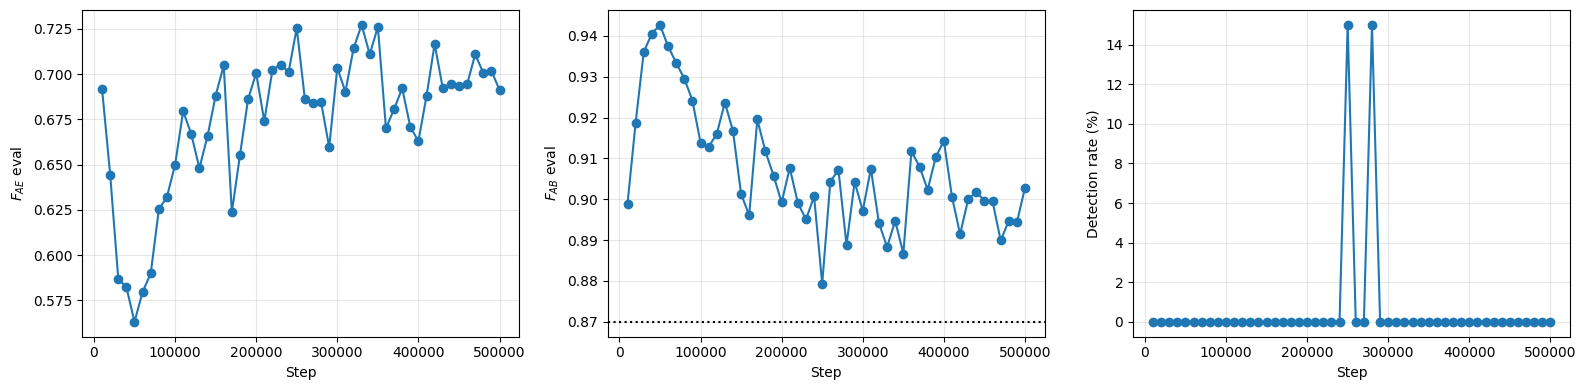

In [92]:
hist_df = pd.DataFrame(best_cb.history)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(hist_df["step"], hist_df["f_ae"], "o-")
axes[0].set_xlabel("Step"); axes[0].set_ylabel("$F_{AE}$ eval"); axes[0].grid(alpha=0.3)
axes[1].plot(hist_df["step"], hist_df["f_ab"], "o-")
axes[1].axhline(F_THRESHOLD, color="k", ls=":")
axes[1].set_xlabel("Step"); axes[1].set_ylabel("$F_{AB}$ eval"); axes[1].grid(alpha=0.3)
axes[2].plot(hist_df["step"], hist_df["det"] * 100, "o-")
axes[2].set_xlabel("Step"); axes[2].set_ylabel("Detection rate (%)"); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

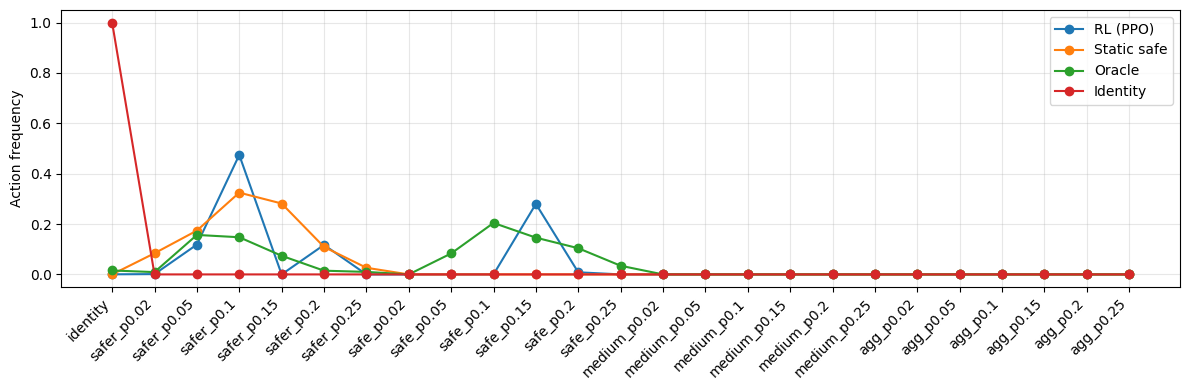

In [93]:
fig, ax = plt.subplots(figsize=(12, 4))
for name, r in results.items():
    counts = np.bincount(r["actions"], minlength=N_ACTIONS)
    ax.plot(range(N_ACTIONS), counts / counts.sum(), "o-", label=name)
ax.set_xticks(range(N_ACTIONS))
ax.set_xticklabels(library_labels, rotation=45, ha="right")
ax.set_ylabel("Action frequency")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [94]:
with open("exp5_results.pkl", "wb") as f:
    pickle.dump({
        "results": results,
        "history": best_cb.history,
        "best_step": best_cb.best_step,
        "best_score": best_cb.best_score,
    }, f)
print("saved exp5_results.pkl")


saved exp5_results.pkl
